
# Problem Statement 7: Examine Experience, Education, Applicants and Career Indicators

## Objective

The objective of this analysis is to examine experience requirements, experience levels, educational qualifications, applicant counts, interview difficulty, probation periods, shift types, active status and career growth indicators.

We will use descriptive statistics, category counts, percentages, visualizations and comparisons to understand the patterns present in the cleaned dataset.

## Scope

This analysis is descriptive only.

Applicant counts are not a measure of hiring probability. The career_growth_index is a supplied field whose definition is undocumented and will not be interpreted as a validated forecast or guaranteed growth. Active status will be analysed descriptively only.

In [27]:
# Importing libraries and loading the cleaned dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load the cleaned dataset. Keep this notebook in the same folder as the CSV.
career_data = pd.read_csv("indian_tech_career_intelligence_2026_cleaned.csv")

print("Cleaned dataset loaded successfully.")

Cleaned dataset loaded successfully.


## 1. Missing Value Analysis

This step calculates the missing-value count and percentage for each of the nine required fields.
It distinguishes actual null values from text categories such as “Not Specified,” which may encode unavailable information.
The missingness chart is designed to remain informative even when every selected field has zero null values.

**Purpose:**

To assess whether the fields are complete before interpreting their distributions.
To avoid treating a meaningful unavailable-information category as an actual null or as a zero value.

In [28]:
# Summarizing missing values in the required fields

required_columns = [
    "experience_required",
    "experience_level",
    "education_required",
    "applicant_count",
    "interview_difficulty",
    "probation_period",
    "shift_type",
    "is_active",
    "career_growth_index"
]

missing_summary = pd.DataFrame({
    "Missing_Count": career_data[required_columns].isna().sum(),
    "Missing_Percentage": (career_data[required_columns].isna().mean() * 100).round(2)
})

display(missing_summary)

,Missing_Count,Missing_Percentage
experience_required,0,0.0
experience_level,0,0.0
education_required,0,0.0
applicant_count,0,0.0
interview_difficulty,0,0.0
probation_period,0,0.0
shift_type,0,0.0
is_active,0,0.0
career_growth_index,0,0.0


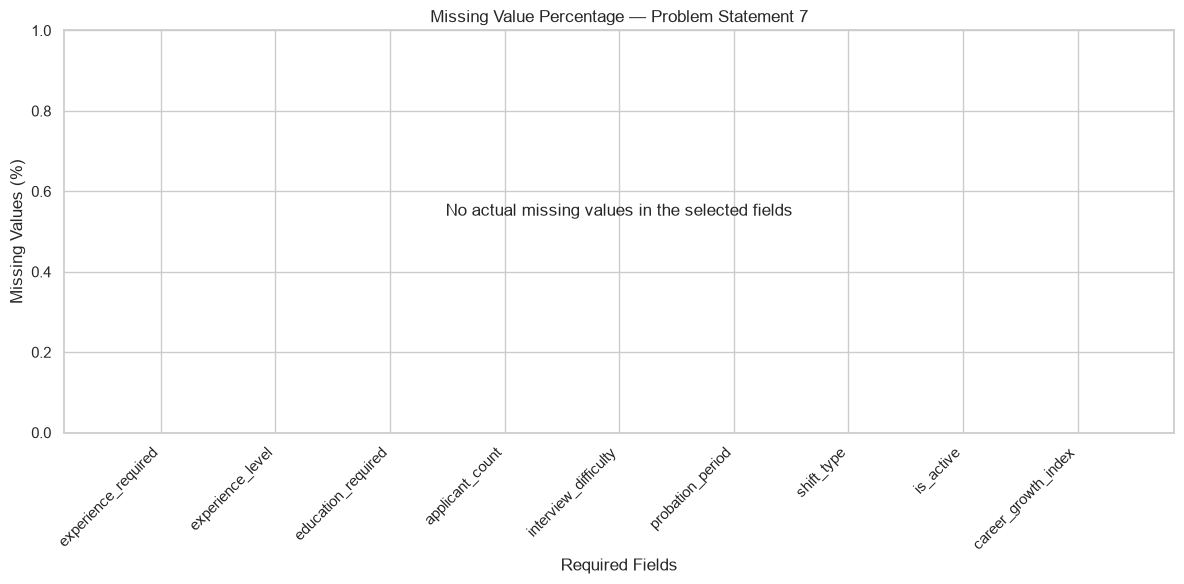

In [29]:
# Visualizing missing-value percentages

plt.figure(figsize=(12, 6))
plt.bar(
    missing_summary.index.astype(str),
    missing_summary["Missing_Percentage"]
)
plt.title("Missing Value Percentage — Problem Statement 7")
plt.xlabel("Required Fields")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45, ha="right")

if missing_summary["Missing_Percentage"].eq(0).all():
    plt.ylim(0, 1)
    plt.text(
        0.5, 0.55,
        "No actual missing values in the selected fields",
        transform=plt.gca().transAxes,
        ha="center",
        va="center"
    )

plt.tight_layout()
plt.show()

### Category Counts and Percentages

The following reusable function reports the count and share of every category, including actual null values.
Percentages use the total number of rows as the denominator, so the categories sum to 100% when all rows are represented.
The function is used for the categorical fields required by Problem Statement 7.

**Purpose:**
To keep category summaries consistent and easy to compare across fields.
To make missing categories visible rather than silently excluding them.

In [30]:
# Creating a reusable category-count and percentage summary

def category_summary(data, column):
    counts = data[column].value_counts(dropna=False)
    summary = pd.DataFrame({
        "Record_Count": counts,
        "Percentage": (counts / len(data) * 100).round(2)
    })
    summary.index.name = column
    return summary

## 2. Experience Requirement Analysis

This analysis summarizes the experience requirements stated in the job records.
It reports each category’s record count and percentage and visualizes the distribution.
The categories describe listed requirements and should not be read as a probability of receiving a job.

**Purpose:**

To identify which experience requirements are most frequently represented in the supplied records.
To describe the distribution of experience expectations without making hiring-probability claims.

In [31]:
# Summarizing experience requirement categories

experience_required_summary = category_summary(career_data, "experience_required")
display(experience_required_summary)

,Record_Count,Percentage
experience_required,,
2-4 Years,59871,59.87
0-1 Years,40129,40.13


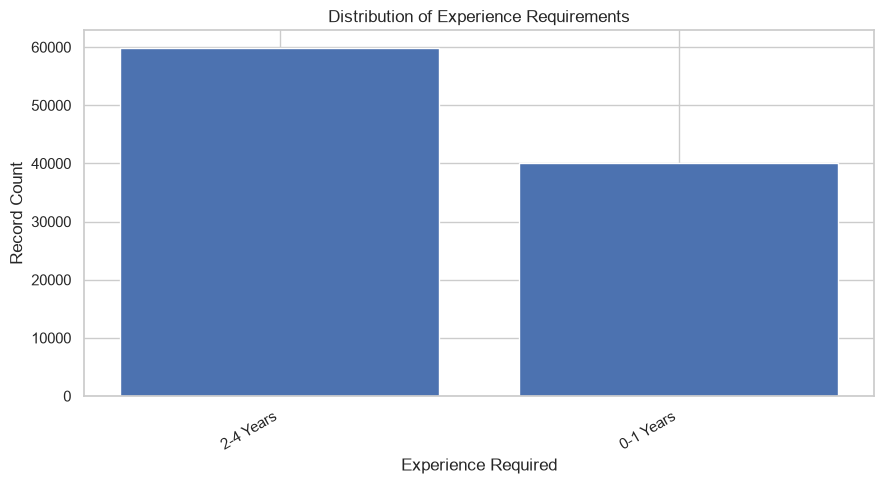

In [32]:
# Visualizing experience requirement categories

experience_counts_for_plot = career_data["experience_required"].value_counts(dropna=False)
plt.figure(figsize=(9, 5))
plt.bar(experience_counts_for_plot.index.map(str), experience_counts_for_plot.values)
plt.title("Distribution of Experience Requirements")
plt.xlabel("Experience Required")
plt.ylabel("Record Count")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 3. Experience Level Analysis

This analysis summarizes the experience-level labels associated with the job records.
It reports category counts and percentages and compares experience level with experience required using a cross-tabulation.
The two fields are examined together but are not assumed to have identical meanings.

**Purpose:**

To understand how the supplied experience levels are distributed and how they align with experience requirements.
To make the relationship between these two related fields visible using counts and within-group percentages.

In [33]:
# Summarizing experience levels and comparing them with requirements

experience_level_summary = category_summary(career_data, "experience_level")
display(experience_level_summary)

experience_level_by_required = pd.crosstab(
    career_data["experience_required"],
    career_data["experience_level"],
    margins=True,
    dropna=False
)
display(experience_level_by_required)

experience_level_by_required_pct = pd.crosstab(
    career_data["experience_required"],
    career_data["experience_level"],
    normalize="index",
    dropna=False
) * 100
display(experience_level_by_required_pct.round(2))

,Record_Count,Percentage
experience_level,,
Mid-Senior Level,59871,59.87
Freshers / Entry Level,40129,40.13


experience_level,Freshers / Entry Level,Mid-Senior Level,All
experience_required,,,
0-1 Years,40129,0,40129
2-4 Years,0,59871,59871
All,40129,59871,100000


experience_level,Freshers / Entry Level,Mid-Senior Level
experience_required,,
0-1 Years,100.0,0.0
2-4 Years,0.0,100.0


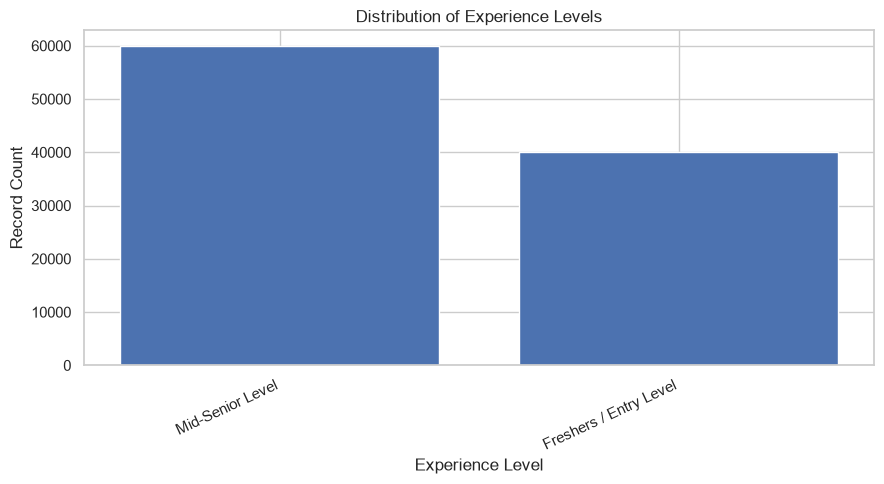

In [34]:
# Visualizing experience level categories

experience_level_counts_for_plot = career_data["experience_level"].value_counts(dropna=False)
plt.figure(figsize=(9, 5))
plt.bar(experience_level_counts_for_plot.index.map(str), experience_level_counts_for_plot.values)
plt.title("Distribution of Experience Levels")
plt.xlabel("Experience Level")
plt.ylabel("Record Count")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 4. Education Requirement Analysis

This analysis summarizes the educational qualifications specified in the job records.
It reports category counts and percentages and compares education requirements across experience levels.
The results describe the qualifications listed in this dataset and do not imply that a qualification guarantees employment.

**Purpose:**

To identify the education categories most frequently represented in the supplied records.
To examine how listed education requirements are distributed across experience levels without making causal claims.

In [35]:
# Summarizing education categories and comparing them by experience

education_summary = category_summary(career_data, "education_required")
display(education_summary)

education_by_experience_counts = pd.crosstab(
    career_data["experience_level"],
    career_data["education_required"],
    margins=True,
    dropna=False
)
display(education_by_experience_counts)

education_by_experience_pct = pd.crosstab(
    career_data["experience_level"],
    career_data["education_required"],
    normalize="index",
    dropna=False
) * 100
display(education_by_experience_pct.round(2))

,Record_Count,Percentage
education_required,,
Bachelor's Degree,33414,33.41
MCA / MSc,33349,33.35
B.E. / B.Tech,33237,33.24


education_required,B.E. / B.Tech,Bachelor's Degree,MCA / MSc,All
experience_level,,,,
Freshers / Entry Level,13324,13395,13410,40129
Mid-Senior Level,19913,20019,19939,59871
All,33237,33414,33349,100000


education_required,B.E. / B.Tech,Bachelor's Degree,MCA / MSc
experience_level,,,
Freshers / Entry Level,33.20,33.38,33.42
Mid-Senior Level,33.26,33.44,33.30


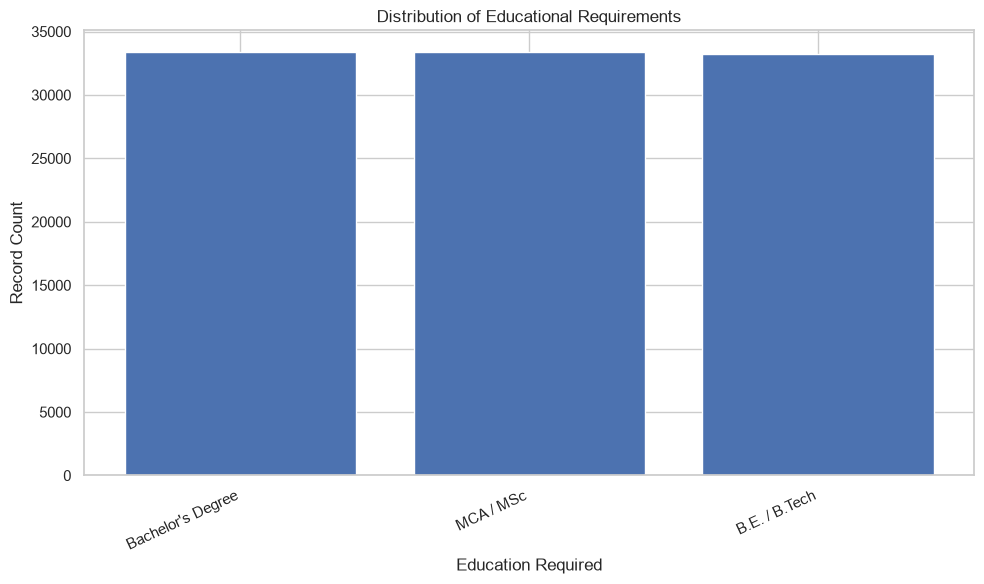

In [36]:
# Visualizing education requirement categories

education_counts_for_plot = career_data["education_required"].value_counts(dropna=False)
plt.figure(figsize=(10, 6))
plt.bar(education_counts_for_plot.index.map(str), education_counts_for_plot.values)
plt.title("Distribution of Educational Requirements")
plt.xlabel("Education Required")
plt.ylabel("Record Count")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 5. Applicant Count Analysis

This analysis describes applicant_count using count, mean, median, spread and range statistics.
It visualizes the distribution and compares summary statistics across relevant experience, education, interview and shift categories.
Applicant counts may be platform snapshots and are not a measure of hiring probability, selection probability or verified competition for a vacancy.

**Purpose:**

To describe the observed applicant-count distribution and how its values vary across selected record categories.
To interpret these values only as supplied snapshots, not as hiring outcomes or selection likelihood.

In [37]:
# Summarizing applicant count statistics

applicant_statistics = career_data["applicant_count"].describe().to_frame(
    name="Applicant_Count"
)
display(applicant_statistics)

,Applicant_Count
count,100000.000000
mean,246.924030
std,134.472691
min,15.000000
25%,130.000000
50%,247.000000
75%,363.000000
max,479.000000


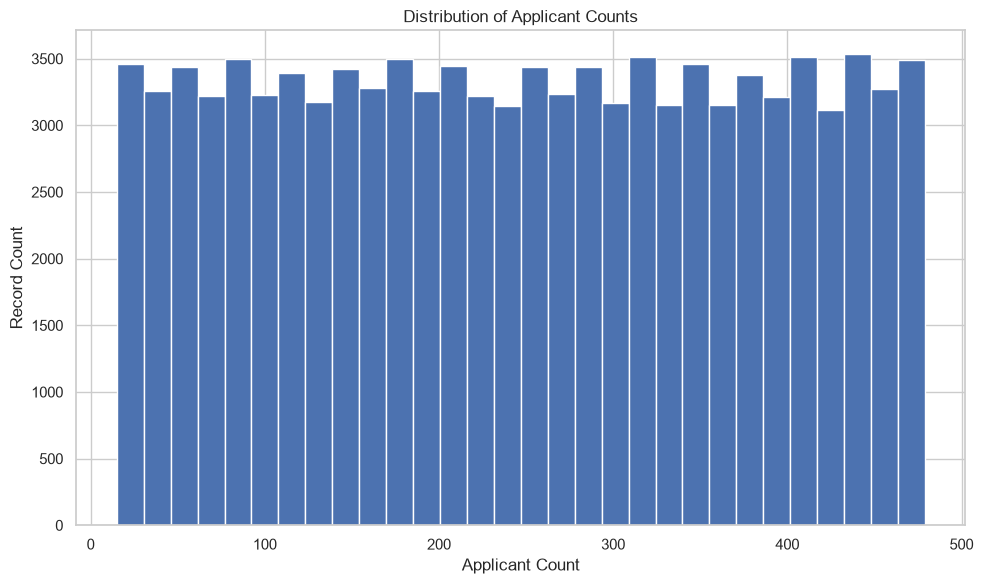

In [38]:
# Visualizing the applicant count distribution

plt.figure(figsize=(10, 6))
plt.hist(career_data["applicant_count"].dropna(), bins=30)
plt.title("Distribution of Applicant Counts")
plt.xlabel("Applicant Count")
plt.ylabel("Record Count")
plt.tight_layout()
plt.show()

C:\Users\murar\AppData\Local\Temp\ipykernel_13880\1534594519.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(career_data["applicant_count"].dropna(), vert=False)


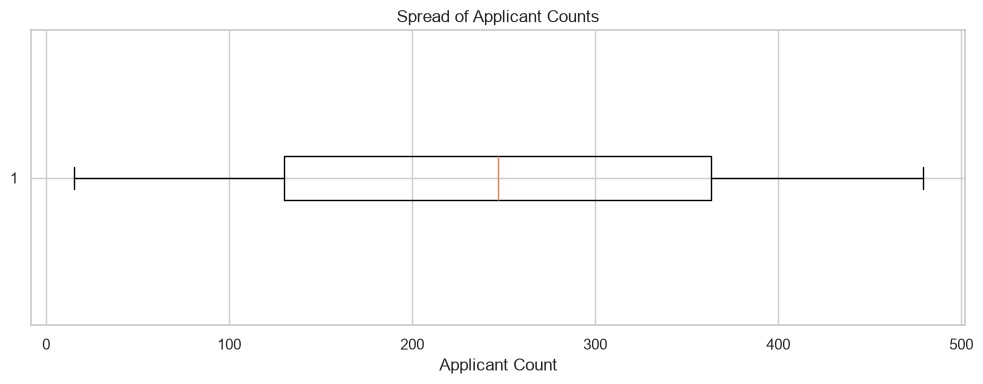

In [39]:
# Visualizing the spread of applicant counts

plt.figure(figsize=(10, 4))
plt.boxplot(career_data["applicant_count"].dropna(), vert=False)
plt.title("Spread of Applicant Counts")
plt.xlabel("Applicant Count")
plt.tight_layout()
plt.show()

In [40]:
# Comparing applicant counts across relevant job categories

applicant_comparison_fields = [
    "experience_required",
    "experience_level",
    "education_required",
    "interview_difficulty",
    "shift_type"
]

for column in applicant_comparison_fields:
    print(f"Applicant count by {column}")
    applicant_comparison = (
        career_data.groupby(column, dropna=False)["applicant_count"]
        .agg(
            Record_Count="count",
            Mean_Applicants="mean",
            Median_Applicants="median",
            Minimum="min",
            Maximum="max"
        )
        .round(2)
    )
    display(applicant_comparison)

Applicant count by experience_required


,Record_Count,Mean_Applicants,Median_Applicants,Minimum,Maximum
experience_required,,,,,
0-1 Years,40129,246.00,246.0,15,479
2-4 Years,59871,247.55,248.0,15,479


Applicant count by experience_level


,Record_Count,Mean_Applicants,Median_Applicants,Minimum,Maximum
experience_level,,,,,
Freshers / Entry Level,40129,246.00,246.0,15,479
Mid-Senior Level,59871,247.55,248.0,15,479


Applicant count by education_required


,Record_Count,Mean_Applicants,Median_Applicants,Minimum,Maximum
education_required,,,,,
B.E. / B.Tech,33237,246.94,247.0,15,479
Bachelor's Degree,33414,246.46,246.0,15,479
MCA / MSc,33349,247.37,248.0,15,479


Applicant count by interview_difficulty


,Record_Count,Mean_Applicants,Median_Applicants,Minimum,Maximum
interview_difficulty,,,,,
Easy,20095,247.65,247.0,15,479
Hard,19889,245.48,244.0,15,479
Medium,60016,247.16,248.0,15,479


Applicant count by shift_type


,Record_Count,Mean_Applicants,Median_Applicants,Minimum,Maximum
shift_type,,,,,
Day Shift,69725,246.76,247.0,15,479
Flexible Shift,20272,247.20,247.0,15,479
Night Shift,10003,247.47,247.0,15,479


## 6. Interview Difficulty Analysis

This analysis reports the counts and percentages of the supplied interview-difficulty categories.
It compares interview difficulty across experience levels and educational qualifications using cross-tabulations.
These labels are treated as supplied categories and do not establish the actual difficulty experienced by every candidate.

**Purpose:**

To understand how interview-difficulty labels are distributed across the records and selected job attributes.
To identify descriptive patterns without claiming that education or experience causes interview difficulty.

In [41]:
# Summarizing interview difficulty categories and comparisons

interview_difficulty_summary = category_summary(career_data, "interview_difficulty")
display(interview_difficulty_summary)

interview_by_experience_counts = pd.crosstab(
    career_data["experience_level"],
    career_data["interview_difficulty"],
    margins=True,
    dropna=False
)
display(interview_by_experience_counts)

interview_by_experience_pct = pd.crosstab(
    career_data["experience_level"],
    career_data["interview_difficulty"],
    normalize="index",
    dropna=False
) * 100
display(interview_by_experience_pct.round(2))

interview_by_education_counts = pd.crosstab(
    career_data["education_required"],
    career_data["interview_difficulty"],
    margins=True,
    dropna=False
)
display(interview_by_education_counts)

,Record_Count,Percentage
interview_difficulty,,
Medium,60016,60.02
Easy,20095,20.10
Hard,19889,19.89


interview_difficulty,Easy,Hard,Medium,All
experience_level,,,,
Freshers / Entry Level,8128,7952,24049,40129
Mid-Senior Level,11967,11937,35967,59871
All,20095,19889,60016,100000


interview_difficulty,Easy,Hard,Medium
experience_level,,,
Freshers / Entry Level,20.25,19.82,59.93
Mid-Senior Level,19.99,19.94,60.07


interview_difficulty,Easy,Hard,Medium,All
education_required,,,,
B.E. / B.Tech,6707,6674,19856,33237
Bachelor's Degree,6732,6556,20126,33414
MCA / MSc,6656,6659,20034,33349
All,20095,19889,60016,100000


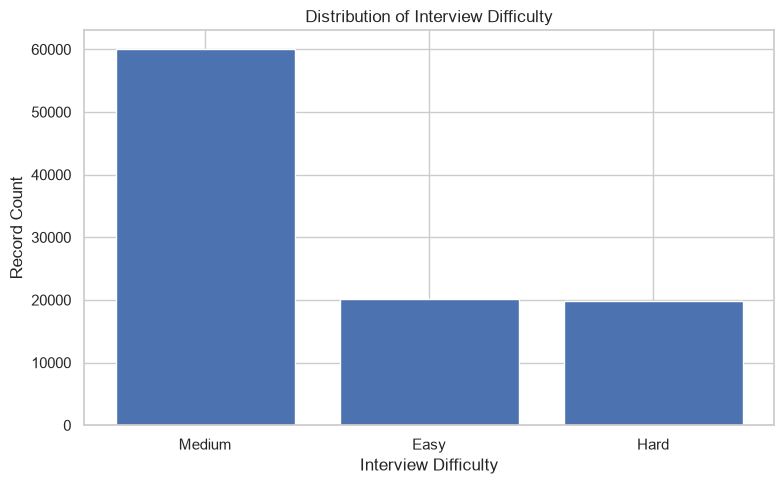

In [42]:
# Visualizing interview difficulty categories

interview_counts_for_plot = career_data["interview_difficulty"].value_counts(dropna=False)
plt.figure(figsize=(8, 5))
plt.bar(interview_counts_for_plot.index.map(str), interview_counts_for_plot.values)
plt.title("Distribution of Interview Difficulty")
plt.xlabel("Interview Difficulty")
plt.ylabel("Record Count")
plt.tight_layout()
plt.show()

## 7. Probation Period Analysis

This analysis summarizes the probation-period categories recorded for the listed jobs.
It reports category counts and percentages and separately distinguishes specified periods from “Not Specified” entries.
“Not Specified” indicates unavailable probation information and must not be interpreted as a zero-month probation period.

**Purpose:**

To describe the probation information available in the dataset and quantify how much is unspecified.
To avoid incorrectly treating missing or unavailable probation details as a confirmed absence of probation.

In [43]:
# Summarizing probation period categories

probation_summary = category_summary(career_data, "probation_period")
display(probation_summary)

probation_text = career_data["probation_period"].astype("string").str.strip()
probation_information_status = probation_text.map(
    lambda value: "Not Specified"
    if pd.isna(value) or value.casefold() == "not specified"
    else "Specified"
)
probation_information_summary = category_summary(
    probation_information_status.to_frame(name="Probation_Information"),
    "Probation_Information"
)
display(probation_information_summary)

,Record_Count,Percentage
probation_period,,
Not Specified,33499,33.50
6 Months,33443,33.44
3 Months,33058,33.06


,Record_Count,Percentage
Probation_Information,,
Specified,66501,66.5
Not Specified,33499,33.5


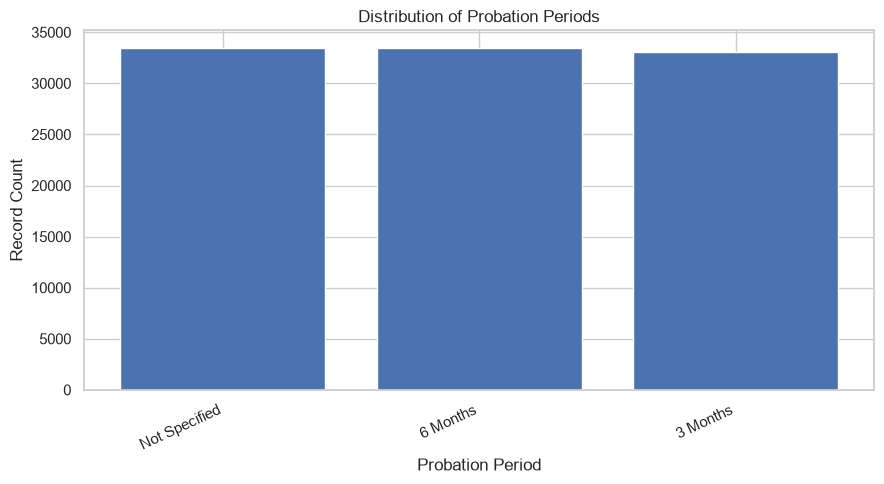

In [44]:
# Visualizing probation period categories

probation_counts_for_plot = career_data["probation_period"].value_counts(dropna=False)
plt.figure(figsize=(9, 5))
plt.bar(probation_counts_for_plot.index.map(str), probation_counts_for_plot.values)
plt.title("Distribution of Probation Periods")
plt.xlabel("Probation Period")
plt.ylabel("Record Count")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 8. Shift Type Analysis

This analysis reports the frequency and percentage of each supplied shift-type category.
It visualizes the distribution and compares shift types across experience levels.
The categories describe the shift labels in these records and do not establish an individual candidate’s preference or suitability.

**Purpose:**

To identify the shift types most frequently represented in the supplied job records.
To describe how shift categories are represented across experience levels without extending beyond the dataset.

In [45]:
# Summarizing shift type categories and comparing them by experience

shift_type_summary = category_summary(career_data, "shift_type")
display(shift_type_summary)

shift_by_experience_counts = pd.crosstab(
    career_data["experience_level"],
    career_data["shift_type"],
    margins=True,
    dropna=False
)
display(shift_by_experience_counts)

shift_by_experience_pct = pd.crosstab(
    career_data["experience_level"],
    career_data["shift_type"],
    normalize="index",
    dropna=False
) * 100
display(shift_by_experience_pct.round(2))

,Record_Count,Percentage
shift_type,,
Day Shift,69725,69.73
Flexible Shift,20272,20.27
Night Shift,10003,10.00


shift_type,Day Shift,Flexible Shift,Night Shift,All
experience_level,,,,
Freshers / Entry Level,28023,8113,3993,40129
Mid-Senior Level,41702,12159,6010,59871
All,69725,20272,10003,100000


shift_type,Day Shift,Flexible Shift,Night Shift
experience_level,,,
Freshers / Entry Level,69.83,20.22,9.95
Mid-Senior Level,69.65,20.31,10.04


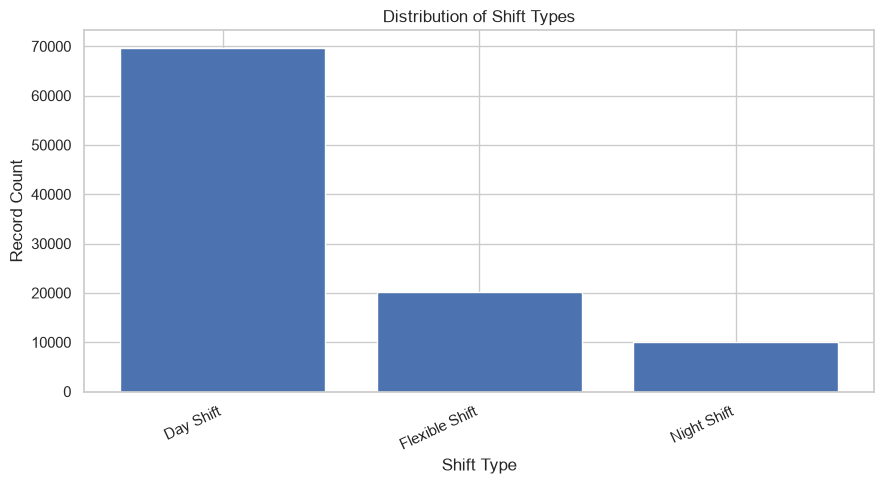

In [46]:
# Visualizing shift type categories

shift_counts_for_plot = career_data["shift_type"].value_counts(dropna=False)
plt.figure(figsize=(9, 5))
plt.bar(shift_counts_for_plot.index.map(str), shift_counts_for_plot.values)
plt.title("Distribution of Shift Types")
plt.xlabel("Shift Type")
plt.ylabel("Record Count")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 9. Active Status Analysis

This analysis reports the number and percentage of records marked active or inactive.
It presents the supplied status distribution without using it to infer current vacancy availability, applications being accepted or employer verification.
Active status is analysed descriptively only, as required by Problem Statement 7.

**Purpose:**

To summarize how active and inactive labels appear in the dataset at the time represented by its records.
To avoid interpreting the status field as live or verified vacancy information.

In [47]:
# Summarizing active and inactive status counts

active_status_summary = category_summary(career_data, "is_active")
display(active_status_summary)

,Record_Count,Percentage
is_active,,
True,85043,85.04
False,14957,14.96


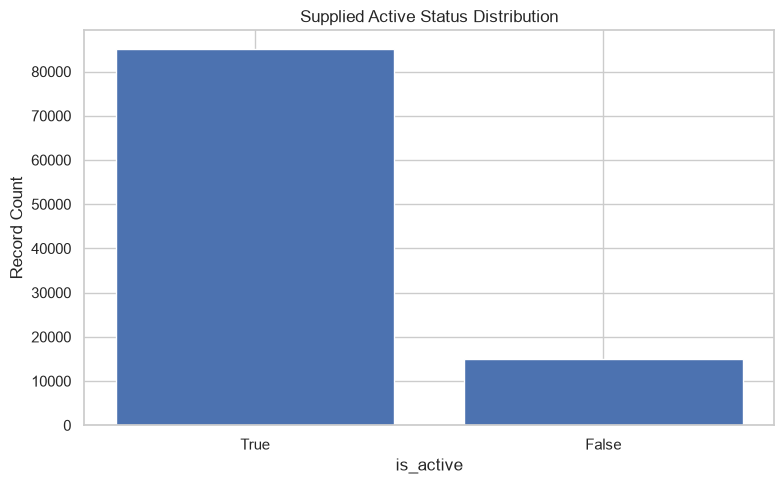

In [48]:
# Visualizing the supplied active status categories

active_counts_for_plot = career_data["is_active"].value_counts(dropna=False)
plt.figure(figsize=(8, 5))
plt.bar(active_counts_for_plot.index.map(str), active_counts_for_plot.values)
plt.title("Supplied Active Status Distribution")
plt.xlabel("is_active")
plt.ylabel("Record Count")
plt.tight_layout()
plt.show()

## 10. Career Growth Indicator Analysis

This analysis describes the supplied career_growth_index using summary statistics and a distribution plot.
It also summarizes the indicator across experience levels to show descriptive differences between groups.
Its definition and methodology are undocumented, so it is not treated as a validated forecast, guaranteed growth, salary growth or promotion probability.

**Purpose:**

To understand the distribution of the numeric indicator as it is supplied in the dataset.
To keep interpretations descriptive and explicitly avoid claims of validated or guaranteed future career growth.

In [49]:
# Summarizing the supplied career growth indicator

career_growth_statistics = career_data["career_growth_index"].describe().to_frame(
    name="Career_Growth_Index"
)
display(career_growth_statistics)

,Career_Growth_Index
count,100000.000000
mean,81.506970
std,9.819165
min,65.000000
25%,73.000000
50%,82.000000
75%,90.000000
max,98.000000


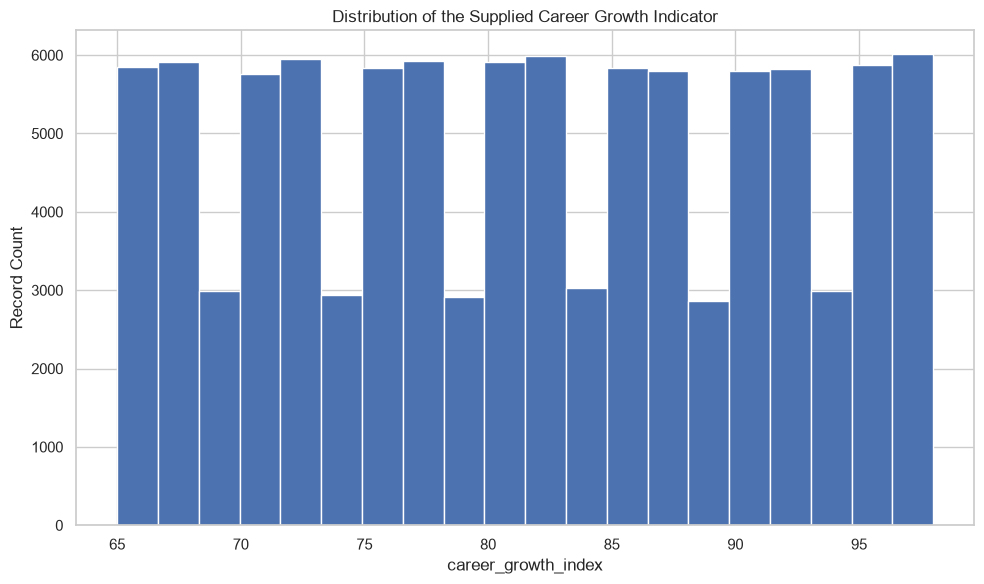

In [50]:
# Visualizing the career growth indicator distribution

plt.figure(figsize=(10, 6))
plt.hist(career_data["career_growth_index"].dropna(), bins=20)
plt.title("Distribution of the Supplied Career Growth Indicator")
plt.xlabel("career_growth_index")
plt.ylabel("Record Count")
plt.tight_layout()
plt.show()

In [51]:
# Comparing the career growth indicator across experience levels

career_growth_by_experience = (
    career_data.groupby("experience_level", dropna=False)["career_growth_index"]
    .agg(
        Record_Count="count",
        Mean_Indicator="mean",
        Median_Indicator="median",
        Minimum="min",
        Maximum="max"
    )
    .round(2)
)
display(career_growth_by_experience)

,Record_Count,Mean_Indicator,Median_Indicator,Minimum,Maximum
experience_level,,,,,
Freshers / Entry Level,40129,81.50,81.0,65,98
Mid-Senior Level,59871,81.51,82.0,65,98


## 11. Consolidated Category Counts

This step combines category counts and percentages for the categorical fields required by the problem statement.
Actual null values are retained as a visible category in each summary rather than being omitted.
The resulting table provides a single place to review category representation across the selected fields.

**Purpose:**

To make category distributions easier to compare and reference in the final hackathon report.
To ensure the required category counts are reported consistently for all categorical fields.

In [52]:
# Combining category counts and percentages into one summary

categorical_fields = [
    "experience_required",
    "experience_level",
    "education_required",
    "interview_difficulty",
    "probation_period",
    "shift_type",
    "is_active"
]

category_summaries = []

for column in categorical_fields:
    counts = career_data[column].value_counts(dropna=False)
    summary = pd.DataFrame({
        "Variable": column,
        "Category": counts.index.map(
            lambda value: "<Missing>" if pd.isna(value) else str(value)
        ),
        "Record_Count": counts.to_numpy(),
        "Percentage": (counts.to_numpy() / len(career_data) * 100).round(2)
    })
    category_summaries.append(summary)

consolidated_category_summary = pd.concat(
    category_summaries,
    ignore_index=True
)
display(consolidated_category_summary)

,Variable,Category,Record_Count,Percentage
0,experience_required,2-4 Years,59871,59.87
1,experience_required,0-1 Years,40129,40.13
2,experience_level,Mid-Senior Level,59871,59.87
3,experience_level,Freshers / Entry Level,40129,40.13
4,education_required,Bachelor's Degree,33414,33.41
5,education_required,MCA / MSc,33349,33.35
6,education_required,B.E. / B.Tech,33237,33.24
7,interview_difficulty,Medium,60016,60.02
8,interview_difficulty,Easy,20095,20.10
9,interview_difficulty,Hard,19889,19.89


## 12. Conclusion

This notebook described the experience, education, applicant, interview, probation, shift, active-status and career-indicator fields named in Problem Statement 7.
It used missingness summaries, category counts, descriptive statistics, plots and comparisons where those comparisons were meaningful.
The conclusions remain limited to the supplied dataset and do not establish causation, hiring probability or guaranteed career outcomes.

**Purpose:**

To consolidate the descriptive evidence into a clear account of the dataset’s observed patterns.
To communicate findings responsibly by preserving the problem statement’s limitations on applicant counts, active status and career_growth_index.